# Healthcare Data Quality Assessment

**Case study:** Symptom-based disease classification dataset  

**Client problem:** A health-related dataset may contain duplicates, inconsistent labels, and train/test contamination that distort predictive performance.

**Service demonstrated:** Data cleaning, reproducible quality checks, EDA, overlap detection, and cautious interpretation of exploratory modeling.

**Potential deliverables for clients:**
1. Data quality summary (missingness, duplicates, schema checks).
2. Cleaned, documented dataset (when licensed and authorized).
3. Reproducible Python notebook.
4. Descriptive plots and short findings report.
5. Transparent limitations and recommended next steps.

**Scope:** Analytical support only. No diagnosis, treatment recommendations, regulatory validation, or unsupervised clinical-trial monitoring.

**Provenance note:** The dataset used in this project was obtained from Kaggle and is publicly available for educational and research purposes, subject to its original license.

## 1. Setup and data loading

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42
# Upload Training.csv and Testing.csv through the Colab Files panel first.
TRAIN_PATH = "/content/Training.csv"
TEST_PATH = "/content/Testing.csv"

train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

def prepare_schema(frame):
    frame = frame.copy()
    empty_unnamed = [c for c in frame.columns if c.startswith("Unnamed:") and frame[c].isna().all()]
    frame = frame.drop(columns=empty_unnamed)
    frame.columns = frame.columns.str.strip()
    frame["prognosis"] = frame["prognosis"].astype(str).str.strip()
    return frame

train = prepare_schema(train_raw)
test = prepare_schema(test_raw)
assert "prognosis" in train.columns and "prognosis" in test.columns
features = [c for c in train.columns if c != "prognosis"]
assert set(features) == set(test.columns) - {"prognosis"}, "Feature schema mismatch"
test = test[train.columns]
assert train[features].notna().all().all() and test[features].notna().all().all()
assert set(np.unique(train[features].to_numpy())).issubset({0, 1})
assert set(np.unique(test[features].to_numpy())).issubset({0, 1})
print("Train:", train.shape, "Test:", test.shape)
print("Unique diseases:", train.prognosis.nunique())
train.head()

Train: (4920, 133) Test: (42, 133)
Unique diseases: 41


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


## 2. Data quality audit


In [ ]:
quality_summary = pd.DataFrame({
    "dataset": ["train", "test"],
    "rows": [len(train), len(test)],
    "missing_cells": [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    "exact_duplicate_rows": [int(train.duplicated().sum()), int(test.duplicated().sum())],
    "unique_symptom_patterns": [len(train[features].drop_duplicates()), len(test[features].drop_duplicates())],
    "diagnosis_classes": [train.prognosis.nunique(), test.prognosis.nunique()],
})
display(quality_summary)

conflicting_patterns = train.groupby(features, dropna=False)["prognosis"].nunique()
print("Symptom patterns associated with multiple diagnoses:", int((conflicting_patterns > 1).sum()))

train_unique = train.drop_duplicates().reset_index(drop=True)
test_unique = test.drop_duplicates().reset_index(drop=True)
train_keys = pd.MultiIndex.from_frame(train_unique[features])
test_keys = pd.MultiIndex.from_frame(test_unique[features])
overlap_mask = test_keys.isin(train_keys)
print(f"Test symptom patterns already present in training: {overlap_mask.sum()} / {len(test_unique)}")

# Exact record overlap includes the diagnosis label.
train_record_keys = pd.MultiIndex.from_frame(train_unique)
test_record_keys = pd.MultiIndex.from_frame(test_unique)
exact_overlap = test_record_keys.isin(train_record_keys)
print(f"Exact train/test record overlap: {exact_overlap.sum()} / {len(test_unique)}")

,dataset,rows,missing_cells,exact_duplicate_rows,unique_symptom_patterns,diagnosis_classes
0,train,4920,0,4616,304,41
1,test,42,0,0,42,41


Symptom patterns associated with multiple diagnoses: 0
Test symptom patterns already present in training: 41 / 42
Exact train/test record overlap: 41 / 42


## 3. Exploratory data analysis


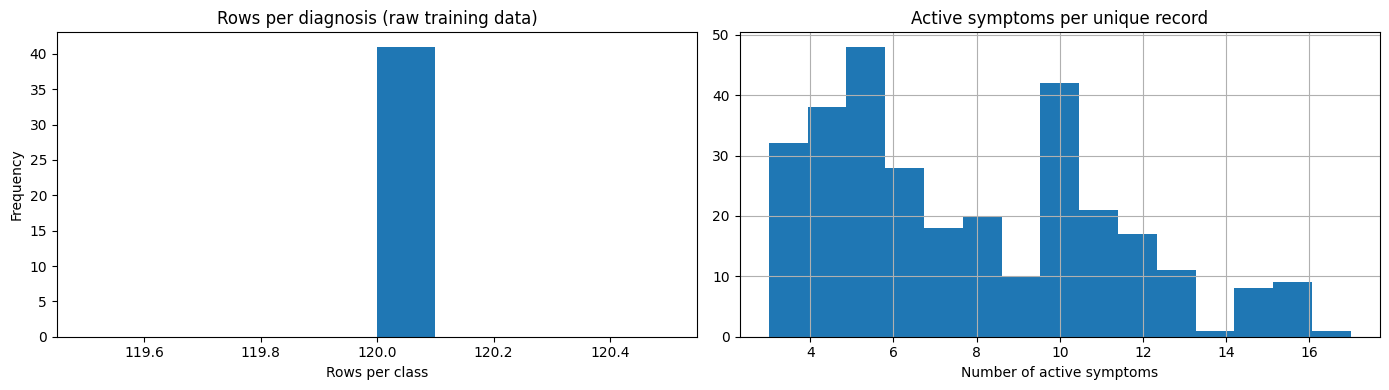

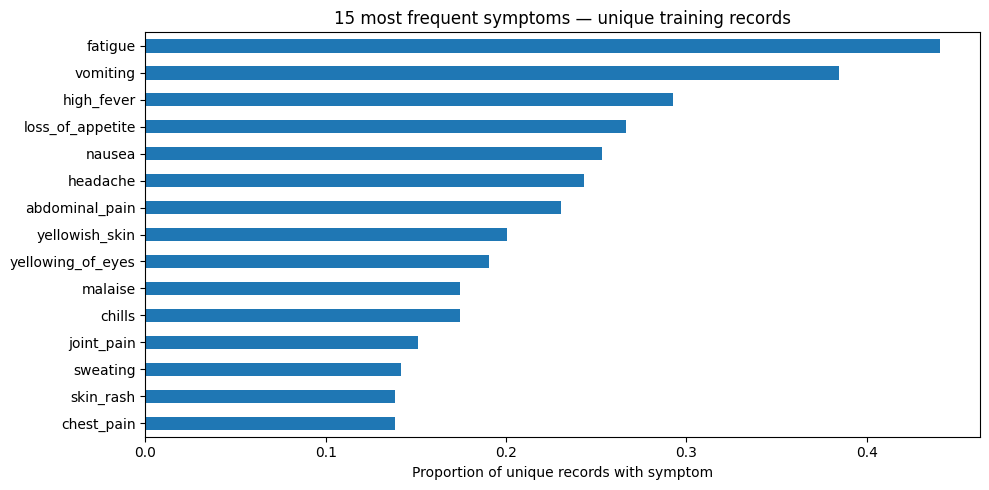

,count,mean,min,max
prognosis,,,,
(vertigo) Paroymsal Positional Vertigo,7,5.142857,5,6
AIDS,5,3.200000,3,4
Acne,5,3.200000,3,4
Alcoholic hepatitis,8,6.125000,6,7
Allergy,5,3.200000,3,4
Arthritis,6,4.166667,4,5
Bronchial Asthma,7,5.142857,5,6
Cervical spondylosis,6,4.166667,4,5
Chicken pox,10,10.100000,10,11


In [ ]:
train_unique = train.drop_duplicates().reset_index(drop=True)
train_unique["total_symptoms"] = train_unique[features].sum(axis=1)
test_descriptive = test.copy()
test_descriptive["total_symptoms"] = test_descriptive[features].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train["prognosis"].value_counts().plot(kind="hist", bins=10, ax=axes[0])
axes[0].set(title="Rows per diagnosis (raw training data)", xlabel="Rows per class")
train_unique["total_symptoms"].hist(bins=15, ax=axes[1])
axes[1].set(title="Active symptoms per unique record", xlabel="Number of active symptoms")
plt.tight_layout()
plt.show()

symptom_frequency = train_unique[features].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
symptom_frequency.head(15).sort_values().plot(kind="barh")
plt.xlabel("Proportion of unique records with symptom")
plt.title("15 most frequent symptoms — unique training records")
plt.tight_layout()
plt.show()

display(train_unique.groupby("prognosis")["total_symptoms"].agg(["count", "mean", "min", "max"]).head(10))

## 4. Exploratory machine learning validation


In [ ]:
X_raw = train[features]
y_raw = train["prognosis"]
original_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
original_model.fit(X_raw, y_raw)
original_predictions = original_model.predict(test[features])
print("ORIGINAL PROVIDED TEST — CONTAMINATED; NOT GENERALIZATION PERFORMANCE")
print("Accuracy:", round(accuracy_score(test.prognosis, original_predictions), 4))
print("Exact overlapping test records:", int(exact_overlap.sum()), "/", len(test))

unique_data = train.drop_duplicates().reset_index(drop=True)
X = unique_data[features]
y = unique_data["prognosis"]
print("Minimum unique records per class:", y.value_counts().min())
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
# Confirm no exact symptom patterns cross the split.
train_pattern_keys = pd.MultiIndex.from_frame(X_train)
holdout_pattern_keys = pd.MultiIndex.from_frame(X_holdout)
assert not holdout_pattern_keys.isin(train_pattern_keys).any()

model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_holdout)
print("\nDEDUPLICATED STRATIFIED HOLDOUT — EXPLORATORY ONLY")
print("Holdout size:", len(X_holdout), "of", len(X))
print("Accuracy:", round(accuracy_score(y_holdout, pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_holdout, pred), 4))
print(classification_report(y_holdout, pred, zero_division=0))

ORIGINAL PROVIDED TEST — CONTAMINATED; NOT GENERALIZATION PERFORMANCE
Accuracy: 0.9762
Exact overlapping test records: 41 / 42
Minimum unique records per class: 5

DEDUPLICATED STRATIFIED HOLDOUT — EXPLORATORY ONLY
Holdout size: 92 of 304
Accuracy: 1.0
Balanced accuracy: 1.0
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         2
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         2
                                Allergy       1.00      1.00      1.00         2
                              Arthritis       1.00      1.00      1.00         2
                       Bronchial Asthma       1.00      1.00      1.00         2
                   Cervical spondylosis       1.00      1.00      1.00     

## 5. Interpretation
The results highlight the importance of data quality,
dataset structure, and appropriate validation strategies
when developing machine learning models for healthcare.

- **Potentially misleading accuracy:** High accuracy on the
  original test set does not necessarily indicate strong
  generalization to unseen patients. Substantial overlap
  between training and testing records may lead to
  data leakage and overly optimistic performance estimates.

- **Impact of deduplication:** Removing duplicate records
  before applying a stratified train-test split reduces
  exact record overlap between datasets. However, this
  approach does not eliminate underlying dataset biases,
  potential synthetic data artifacts, or correlations
  between observations.

- **Class imbalance and limited sample diversity:**
  With 41 diagnostic categories and a limited number
  of unique observations per class, performance estimates
  for individual diagnoses may be unstable and should
  be interpreted cautiously.

## 6. Clinical and Methodological Limitations

- **Limited clinical information:** Binary symptom
  indicators do not capture essential clinical context,
  including patient history, physical examination,
  laboratory findings, or additional diagnostic tests.

- **Lack of external validation:** The model has not
  been evaluated using an independent clinical dataset.
  Therefore, its reliability and generalizability in
  real-world healthcare settings remain unknown.

- **No demonstrated clinical utility:** Predictive
  performance on this dataset does not establish
  diagnostic accuracy, patient safety, or suitability
  for clinical decision-making.

## 7. Recommendations for Future Work

To improve the methodological quality and reliability
of this analysis, future work should focus on:

1. Verifying the dataset's original source, provenance,
   and licensing conditions.
2. Investigating how the observations were collected
   or generated, including potential synthetic patterns.
3. Evaluating the model using genuinely independent
   data to assess generalization.
4. Exploring class-level performance, dataset bias,
   and potential sources of data leakage.
5. Defining a clear, clinically relevant research
   objective before considering predictive applications.


## 8. Final Conclusion

This project demonstrates how data quality assessment,
duplicate detection, and appropriate validation
strategies can substantially influence the interpretation
of machine learning results.

Rather than focusing exclusively on predictive accuracy,
the analysis emphasizes **data integrity, methodological
transparency, and critical evaluation of model
performance**.

**This project is intended for educational and research
purposes only. The model is not validated for clinical
diagnosis or medical decision-making.**